# HW2 — Problem 1: Selective Memory with SSM (50%)

Complete the five model TODOs in the next code cell. Save your completed work as **hw2_1_<StudentID>.ipynb**, including outputs, plots, tables and discussion.

## Getting started
1. Join the [course Kaggle competition](https://www.kaggle.com/t/8c17aaa8718948559394446f43ea896c).
2. Download `train.jsonl`, `val.jsonl`, and `test.jsonl`. Locally or in Colab, place them in `data/`; on Kaggle, attach the competition data using the notebook's Input panel.
3. Use a Python environment with **PyTorch** and **Matplotlib** installed.
4. Complete `basic_init`, `basic_forward`, `gate_init`, `gate_compute`, and `gate_forward`. Then execute the cells in order.

This notebook contains the fixed vocabulary, loader, training loop, checkpoint saving, plots, benchmark and CSV writer. You do not need separate utility Python files.

The next cell creates `hw2_1.py` automatically in the working directory. **Edit TODOs in this notebook cell**: rerunning it overwrites that generated file. Model TODOs intentionally raise `NotImplementedError` until completed.

The task requirements and grading rules are in the assignment PDF. Use only the provided training data for optimization and validation data for model selection.


In [1]:
%%writefile hw2_1.py
"""Provided training/evaluation utilities. Model inputs are tokens only."""
import argparse
import csv
import json
import math
import platform
import random
import time
from collections import defaultdict
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

def fixed_vocab():
    tokens = ['PAD','BOS','SEP','STORE','NOISE','QUERY','ANSWER'] + [f'K{i}' for i in range(32)] + [f'V{i}' for i in range(32)]
    return {token: i for i, token in enumerate(tokens)}

def seed_all(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

class MemoryDataset(Dataset):
    def __init__(self, path, vocab, limit=0):
        self.rows = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
        if limit:
            self.rows = self.rows[:limit]
        if not self.rows:
            raise ValueError(f'Empty dataset: {path}')
        self.ids = [[vocab[t] for t in row['tokens']] for row in self.rows]
        self.labels = [int(row['answer'][1:]) if 'answer' in row else -100 for row in self.rows]
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        return self.ids[i], self.labels[i], self.rows[i]

def collate(samples):
    lengths = torch.tensor([len(x[0]) for x in samples], dtype=torch.long)
    # PAD is ID 0 in the fixed vocabulary.
    tokens = torch.zeros(len(samples), int(lengths.max()), dtype=torch.long)
    for i,(ids,_,_) in enumerate(samples):
        tokens[i,:len(ids)] = torch.tensor(ids)
    return tokens, lengths, torch.tensor([x[1] for x in samples]), [x[2] for x in samples]

def loader(path, vocab, batch_size, shuffle=False, limit=0):
    return DataLoader(MemoryDataset(path,vocab,limit),batch_size=batch_size,shuffle=shuffle,collate_fn=collate,num_workers=0)

class SSMBlock(nn.Module):
    def __init__(self, ssm, d, dropout):
        super().__init__()
        self.ssm=ssm
        self.norm=nn.LayerNorm(d)
        self.act=nn.GELU()
        self.dropout=nn.Dropout(dropout)
    def forward(self,x,return_gates=False):
        y,g=self.ssm(self.norm(x),return_gates=return_gates)
        return x+self.dropout(self.act(y)),g

class MemoryModel(nn.Module):
    def __init__(self, config, basic_class, gated_class):
        super().__init__()
        d,n=config['d'],config['n']
        self.embedding=nn.Embedding(71,d,padding_idx=0)
        layers=[]
        for _ in range(config['layers']):
            ssm=basic_class(d,n) if config['model']=='basic' else gated_class(d,n)
            layers.append(SSMBlock(ssm,d,config['dropout']))
        self.blocks=nn.ModuleList(layers)
        self.norm=nn.LayerNorm(d)
        self.head=nn.Linear(d,32)
    def forward(self,tokens,lengths,return_gates=False):
        x=self.embedding(tokens)
        gates=[]
        for block in self.blocks:
            x,g=block(x,return_gates)
            gates.append(g)
        # Only valid ANSWER representations reach the prediction head.
        last=self.norm(x)[torch.arange(tokens.size(0),device=tokens.device),lengths-1]
        return self.head(last),gates

def sync(device):
    if device.type=='cuda': torch.cuda.synchronize(device)

def on_device(batch,device):
    tokens,lengths,labels,rows=batch
    return tokens.to(device),lengths.to(device),labels.to(device),rows

@torch.no_grad()
def evaluate(model,batches,device,keep=False):
    model.eval()
    total_loss=correct=total=0
    predictions=[]
    for batch in batches:
        tokens,lengths,labels,rows=on_device(batch,device)
        logits,_=model(tokens,lengths)
        pred=logits.argmax(-1)
        valid=labels.ne(-100)
        if valid.any():
            total_loss+=nn.functional.cross_entropy(logits[valid],labels[valid],reduction='sum').item()
            correct+=(pred[valid]==labels[valid]).sum().item()
            total+=valid.sum().item()
        if keep:
            for row,p in zip(rows,pred.cpu().tolist()):
                predictions.append(dict(id=row['id'],prediction=f'V{p}',answer=row.get('answer'),group=row.get('group','all'),tokens=row['tokens']))
    return {'loss':total_loss/total if total else None,'accuracy':correct/total if total else None,'count':total},predictions

def save_json(path,obj):
    Path(path).write_text(json.dumps(obj,indent=2)+'\n')

def plot_history(history,path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(6,4))
    ax.plot([r['epoch'] for r in history],[r['train_loss'] for r in history],label='Training')
    ax.plot([r['epoch'] for r in history],[r['val_loss'] for r in history],label='Validation')
    ax.set(xlabel='Epoch',ylabel='Cross-entropy loss'); ax.legend(); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

def train(args,basic,gated):
    seed_all(args.seed)
    device=resolve_device(args.device)
    config={k:getattr(args,k) for k in ['model','d','n','layers','dropout']}
    model=MemoryModel(config,basic,gated).to(device)
    effective=sum(p.numel() for p in model.parameters() if p.requires_grad)
    if effective>=1000000: raise ValueError('Effective trainable parameter count must be below 1,000,000.')
    vocab=fixed_vocab()
    tr=loader(args.data/'train.jsonl',vocab,args.batch_size,True,args.limit_train)
    va=loader(args.data/'val.jsonl',vocab,args.batch_size,False,args.limit_val)
    optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=args.lr,weight_decay=args.weight_decay)
    out=args.out; out.mkdir(parents=True,exist_ok=True)
    best=(-1.,float('-inf')); history=[]
    if device.type=='cuda': torch.cuda.reset_peak_memory_stats(device)
    peak_training=0
    environment={'torch':torch.__version__,'python':platform.python_version(),'device':str(device),'device_name':torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor(),'precision':'float32','threads':torch.get_num_threads()}
    for epoch in range(1,args.epochs+1):
        model.train(); total=loss_sum=0
        if device.type=='cuda': torch.cuda.reset_peak_memory_stats(device)
        sync(device); start=time.perf_counter()
        for batch in tr:
            tokens,lengths,labels,_=on_device(batch,device)
            optimizer.zero_grad(set_to_none=True)
            logits,_=model(tokens,lengths)
            loss=nn.functional.cross_entropy(logits,labels)
            if not torch.isfinite(loss): raise RuntimeError('Non-finite loss')
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
            total+=len(labels); loss_sum+=loss.item()*len(labels)
        sync(device); elapsed=time.perf_counter()-start
        if device.type=='cuda': peak_training=max(peak_training,torch.cuda.max_memory_allocated(device))
        sync(device); start=time.perf_counter(); metrics,_=evaluate(model,va,device); sync(device)
        record=dict(epoch=epoch,train_loss=loss_sum/total,val_loss=metrics['loss'],val_accuracy=metrics['accuracy'],train_seconds=elapsed,val_seconds=time.perf_counter()-start)
        history.append(record); print(json.dumps(record),flush=True)
        rank=(metrics['accuracy'],-metrics['loss'])
        if rank>best:
            best=rank
            # No optimizer or executable Python objects in the checkpoint.
            torch.save({'state_dict':model.state_dict(),'config':config,'vocab':vocab,'epoch':epoch,'validation':metrics,'seed':args.seed},out/'best.pt')
        save_json(out/'history.json',history)
    checkpoint=torch.load(out/'best.pt',map_location=device,weights_only=True)
    model.load_state_dict(checkpoint['state_dict']); model.eval()
    inference=benchmark(model,va,device)
    validation, predictions=evaluate(model,va,device,True)
    save_json(out/'failure_examples.json',[row for row in predictions if row['prediction']!=row['answer']][:3])
    plot_history(history,out/'learning_curves.png')
    save_json(out/'run_config.json',{**vars_serializable(args),'environment':environment})
    save_json(out/'training_summary.json',{'effective_trainable_parameters':effective,'total_parameters':sum(p.numel() for p in model.parameters()),'mean_train_seconds_per_epoch':sum(h['train_seconds'] for h in history)/len(history),'inference':inference,'best_validation_accuracy':best[0],'peak_training_allocated_bytes':peak_training if device.type=='cuda' else None,'note':'CPU memory is not GPU allocated memory; no GPU estimate is supplied. Validation excluded from epoch training time.'})

def vars_serializable(args):
    return {k:str(v) if isinstance(v,Path) else v for k,v in vars(args).items()}

def resolve_device(name):
    if name=='auto': name='cuda' if torch.cuda.is_available() else 'cpu'
    device=torch.device(name)
    if device.type=='cuda' and not torch.cuda.is_available(): raise RuntimeError('CUDA requested but unavailable')
    return device

def restore(args,basic,gated):
    device=resolve_device(args.device)
    checkpoint=torch.load(args.checkpoint,map_location=device,weights_only=True)
    model=MemoryModel(checkpoint['config'],basic,gated).to(device)
    model.load_state_dict(checkpoint['state_dict']); model.eval()
    return model,checkpoint['vocab'],device

def predict(args,basic,gated):
    model,vocab,device=restore(args,basic,gated)
    batches=loader(args.input,vocab,args.batch_size)
    _,rows=evaluate(model,batches,device,True)
    args.output.parent.mkdir(parents=True,exist_ok=True)
    with args.output.open('w',newline='') as f:
        w=csv.writer(f); w.writerow(['id','answer']); w.writerows((r['id'],r['prediction']) for r in rows)
    print(f'Wrote {len(rows)} predictions to {args.output}')

@torch.no_grad()
def benchmark(model,batches,device):
    # Time forward only on a fixed padded batch, with copies excluded.
    tokens,lengths,_,_=on_device(next(iter(batches)),device)
    for _ in range(3): model(tokens,lengths)
    sync(device); start=time.perf_counter()
    for _ in range(10): model(tokens,lengths)
    sync(device); seconds=(time.perf_counter()-start)/10
    return dict(forward_batch_seconds=seconds,forward_samples_per_second=tokens.size(0)/seconds,batch_size=tokens.size(0),padded_length=tokens.size(1),timing_scope='10 repeated forwards after 3 warmups; data transfer excluded')


class DiagonalSSM(nn.Module):
    def __init__(self, d, n):
        super().__init__()
        self.d, self.n = d, n
        # TODO: basic_init
        a_init=torch.linspace(0.5,0.99,n)
        self.theta_a=nn.Parameter(torch.log(a_init)-torch.log1p(-a_init))
        self.B=nn.Linear(d,n,bias=False)
        self.C=nn.Linear(n,d,bias=False)
        self.D=nn.Linear(d,d,bias=False)

    def forward(self, x, return_gates=False):
        """x: [batch,length,d]; return (y [batch,length,d], gates or None)."""
        # TODO: basic_forward
        a=torch.sigmoid(self.theta_a)
        u=self.B(x)
        h=x.new_zeros(x.size(0),self.n)
        states=[]
        for t in range(x.size(1)):
            h=a*h+u[:,t]
            states.append(h)
        h=torch.stack(states,dim=1)
        return self.C(h)+self.D(x),None

class GatedDiagonalSSM(DiagonalSSM):
    def __init__(self, d, n):
        super().__init__(d,n)
        # TODO: gate_init
        self.W_g=nn.Linear(d,n,bias=True)
        nn.init.zeros_(self.W_g.bias)

    def forward(self, x, return_gates=False):
        # TODO: gate_compute
        g=torch.sigmoid(self.W_g(x))
        # TODO: gate_forward
        a=torch.sigmoid(self.theta_a)
        u=self.B(x)
        h=x.new_zeros(x.size(0),self.n)
        states=[]
        for t in range(x.size(1)):
            h_candidate=a*h+u[:,t]
            h=(1-g[:,t])*h+g[:,t]*h_candidate
            states.append(h)
        h=torch.stack(states,dim=1)
        return self.C(h)+self.D(x),(g if return_gates else None)


def run_cli(basic,gated):
    parser=argparse.ArgumentParser()
    parser.add_argument('--threads',type=int,default=2)
    sub=parser.add_subparsers(dest='command',required=True)
    t=sub.add_parser('train')
    t.add_argument('--model',choices=['basic','gated'],required=True)
    t.add_argument('--data',type=Path,default=Path('data'));t.add_argument('--out',type=Path,required=True)
    for name,value in [('d',64),('n',64),('layers',2),('epochs',10),('batch-size',64),('seed',42),('limit-train',0),('limit-val',0)]:t.add_argument('--'+name,type=int,default=value)
    t.add_argument('--dropout',type=float,default=.1);t.add_argument('--lr',type=float,default=.001);t.add_argument('--weight-decay',type=float,default=.01);t.add_argument('--device',default='auto')
    q=sub.add_parser('predict');q.add_argument('--checkpoint',type=Path,required=True);q.add_argument('--input',type=Path,required=True);q.add_argument('--output',type=Path,required=True);q.add_argument('--batch-size',type=int,default=64);q.add_argument('--device',default='auto')
    args=parser.parse_args();torch.set_num_threads(args.threads)
    if args.command=='train':train(args,basic,gated)
    else:predict(args,basic,gated)

if __name__=='__main__':run_cli(DiagonalSSM,GatedDiagonalSSM)


Overwriting hw2_1.py


## Data and output directories

Set `DATA_DIR` to the folder containing all three JSONL files. This cell tries `data/`, the current directory, and attached Kaggle input folders. If more than one matching dataset is found, select the course dataset manually. The working directory must be writable.


In [2]:
from pathlib import Path
import subprocess, sys, json

DATA_DIR = Path("data")  # Change this if your files are elsewhere.
REQUIRED_FILES = ("train.jsonl", "val.jsonl", "test.jsonl")
def has_data(folder):
    return all((folder / name).is_file() for name in REQUIRED_FILES)

if not has_data(DATA_DIR):
    candidates = [Path(".")] if has_data(Path(".")) else []
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates += [p.parent for p in kaggle_input.rglob("train.jsonl")
                       if has_data(p.parent)]
    candidates = sorted(set(p.resolve() for p in candidates))
    if len(candidates) == 1:
        DATA_DIR = candidates[0]
    else:
        raise FileNotFoundError(
            "Set DATA_DIR to the course data folder containing "
            + ", ".join(REQUIRED_FILES)
            + f". Matching folders found: {candidates}"
        )
print("Data directory:", DATA_DIR.resolve())

def run(*args):
    subprocess.run([sys.executable, "hw2_1.py", *map(str, args)], check=True)


Data directory: /home/longpm/works/knowledge/llm-nycu/hw2/data


## Small pipeline check — not a formal result

In [3]:
run("train","--model","gated","--data",DATA_DIR,"--out","runs/smoke","--epochs",1,"--limit-train",256,"--limit-val",128)

{"epoch": 1, "train_loss": 3.628258526325226, "val_loss": 3.5509217977523804, "val_accuracy": 0.046875, "train_seconds": 1.7000764030963182, "val_seconds": 0.09193208068609238}


## Q1 and Q2 — identical training settings

In [4]:
for name in ["basic","gated"]:
    run("train","--model",name,"--data",DATA_DIR,"--out",f"runs/{name}")

{"epoch": 1, "train_loss": 3.476898041407267, "val_loss": 3.430369181315104, "val_accuracy": 0.06, "train_seconds": 15.62842677719891, "val_seconds": 0.32224481366574764}


{"epoch": 2, "train_loss": 3.3921587708791097, "val_loss": 3.376403055826823, "val_accuracy": 0.07933333333333334, "train_seconds": 14.622270606458187, "val_seconds": 0.2742744777351618}


{"epoch": 3, "train_loss": 3.3198269685109456, "val_loss": 3.3179633178710937, "val_accuracy": 0.08666666666666667, "train_seconds": 14.99220572784543, "val_seconds": 0.2875720411539078}


{"epoch": 4, "train_loss": 3.2410552775065105, "val_loss": 3.2687766927083333, "val_accuracy": 0.09066666666666667, "train_seconds": 14.401202704757452, "val_seconds": 0.27766526862978935}


{"epoch": 5, "train_loss": 3.160018129348755, "val_loss": 3.1765120951334636, "val_accuracy": 0.11666666666666667, "train_seconds": 14.178744670003653, "val_seconds": 0.2862049136310816}


...

{"epoch": 6, "train_loss": 1.474386573155721, "val_loss": 1.4306475296020509, "val_accuracy": 0.386, "train_seconds": 29.742430364713073, "val_seconds": 0.6455448940396309}


{"epoch": 7, "train_loss": 1.3827508430480957, "val_loss": 1.4111527760823568, "val_accuracy": 0.39266666666666666, "train_seconds": 29.850231923162937, "val_seconds": 0.6603804565966129}


{"epoch": 8, "train_loss": 1.31882244459788, "val_loss": 1.384779067993164, "val_accuracy": 0.386, "train_seconds": 29.60358444415033, "val_seconds": 0.6714392006397247}


{"epoch": 9, "train_loss": 1.253593245824178, "val_loss": 1.3973594919840495, "val_accuracy": 0.36933333333333335, "train_seconds": 29.160620599985123, "val_seconds": 0.6919425334781408}


{"epoch": 10, "train_loss": 1.210447314898173, "val_loss": 1.3903432795206705, "val_accuracy": 0.3913333333333333, "train_seconds": 30.197286318987608, "val_seconds": 0.6676690019667149}


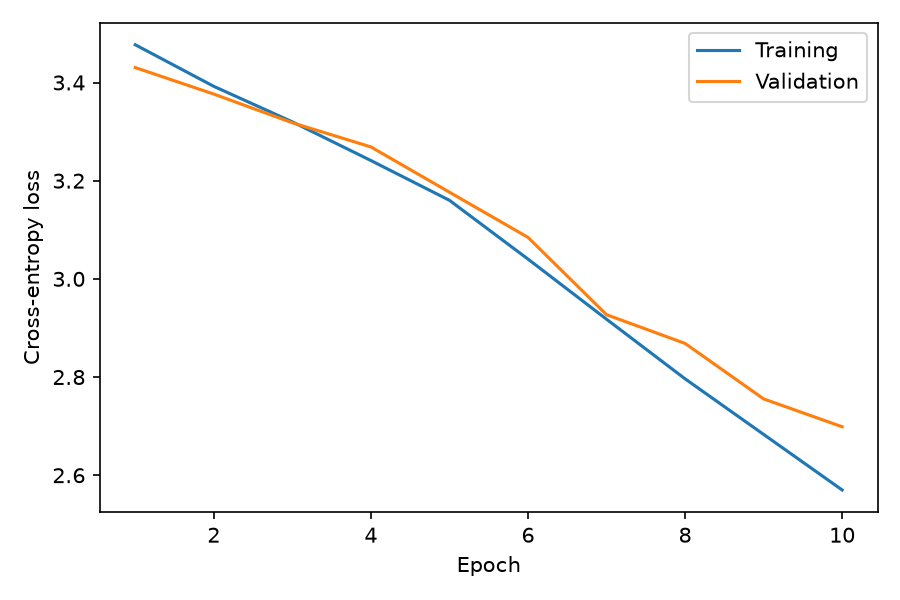

basic {'effective_trainable_parameters': 31712, 'total_parameters': 31712, 'mean_train_seconds_per_epoch': 14.243230374343693, 'inference': {'forward_batch_seconds': 0.008061975799500942, 'forward_samples_per_second': 7938.5006345419415, 'batch_size': 64, 'padded_length': 124, 'timing_scope': '10 repeated forwards after 3 warmups; data transfer excluded'}, 'best_validation_accuracy': 0.234, 'peak_training_allocated_bytes': 47147520, 'note': 'CPU memory is not GPU allocated memory; no GPU estimate is supplied. Validation excluded from epoch training time.'}
Failures: [{'id': 'val_000003', 'prediction': 'V16', 'answer': 'V17', 'group': 'all', 'tokens': ['BOS', 'NOISE', 'K26', 'V6', 'SEP', 'STORE', 'K9', 'V15', 'SEP', 'NOISE', 'K14', 'V18', 'SEP', 'NOISE', 'K12', 'V28', 'SEP', 'NOISE', 'K9', 'V3', 'SEP', 'NOISE', 'K23', 'V28', 'SEP', 'NOISE', 'K30', 'V19', 'SEP', 'NOISE', 'K6', 'V4', 'SEP', 'NOISE', 'K16', 'V15', 'SEP', 'NOISE', 'K13', 'V22', 'SEP', 'NOISE', 'K4', 'V31', 'SEP', 'NOISE', '

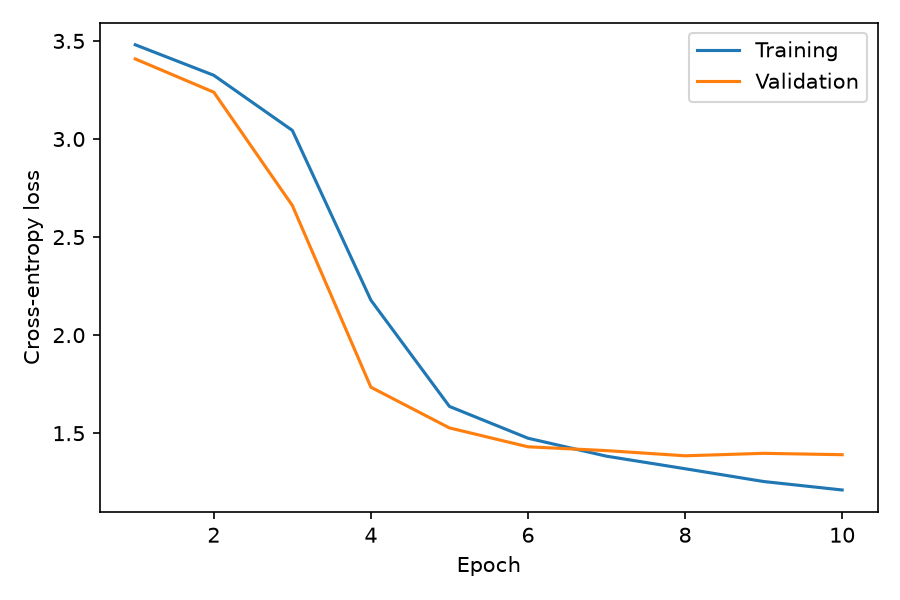

gated {'effective_trainable_parameters': 40032, 'total_parameters': 40032, 'mean_train_seconds_per_epoch': 30.65854367092252, 'inference': {'forward_batch_seconds': 0.023459137231111527, 'forward_samples_per_second': 2728.148071665788, 'batch_size': 64, 'padded_length': 124, 'timing_scope': '10 repeated forwards after 3 warmups; data transfer excluded'}, 'best_validation_accuracy': 0.39866666666666667, 'peak_training_allocated_bytes': 61404672, 'note': 'CPU memory is not GPU allocated memory; no GPU estimate is supplied. Validation excluded from epoch training time.'}
Failures: [{'id': 'val_000001', 'prediction': 'V21', 'answer': 'V19', 'group': 'all', 'tokens': ['BOS', 'NOISE', 'K17', 'V26', 'SEP', 'NOISE', 'K5', 'V27', 'SEP', 'NOISE', 'K31', 'V14', 'SEP', 'NOISE', 'K9', 'V15', 'SEP', 'NOISE', 'K25', 'V8', 'SEP', 'NOISE', 'K10', 'V9', 'SEP', 'NOISE', 'K21', 'V19', 'SEP', 'NOISE', 'K2', 'V23', 'SEP', 'NOISE', 'K26', 'V10', 'SEP', 'NOISE', 'K20', 'V17', 'SEP', 'NOISE', 'K18', 'V19', 'SE

In [5]:
from IPython.display import Image, display
for name in ["basic","gated"]:
    display(Image(filename=f"runs/{name}/learning_curves.png"))
    print(name, json.loads(Path(f"runs/{name}/training_summary.json").read_text()))
    print("Failures:", json.loads(Path(f"runs/{name}/failure_examples.json").read_text()))

In [6]:
import pandas as pd
import torch
from collections import defaultdict
from IPython.display import display
from hw2_1 import DiagonalSSM, GatedDiagonalSSM, MemoryModel, evaluate, fixed_vocab, loader

summaries = {name: json.loads(Path(f"runs/{name}/training_summary.json").read_text()) for name in ["basic", "gated"]}
histories = {name: json.loads(Path(f"runs/{name}/history.json").read_text()) for name in ["basic", "gated"]}
best = {name: max(h, key=lambda r: (r["val_accuracy"], -r["val_loss"])) for name, h in histories.items()}


def peak_mib(summary):
    peak = summary["peak_training_allocated_bytes"]
    return "N/A" if peak is None else f"{peak / 1024**2:.1f}"


q3_table = pd.DataFrame({
    "Basic SSM": [f"{summaries['basic']['effective_trainable_parameters']:,}",
                  f"{best['basic']['val_accuracy']:.4f} (epoch {best['basic']['epoch']})",
                  f"{best['basic']['val_loss']:.4f}",
                  f"{summaries['basic']['mean_train_seconds_per_epoch']:.2f}",
                  f"{summaries['basic']['inference']['forward_samples_per_second']:,.0f}",
                  peak_mib(summaries["basic"])],
    "Gated SSM": [f"{summaries['gated']['effective_trainable_parameters']:,}",
                  f"{best['gated']['val_accuracy']:.4f} (epoch {best['gated']['epoch']})",
                  f"{best['gated']['val_loss']:.4f}",
                  f"{summaries['gated']['mean_train_seconds_per_epoch']:.2f}",
                  f"{summaries['gated']['inference']['forward_samples_per_second']:,.0f}",
                  peak_mib(summaries["gated"])],
}, index=pd.Index(["Trainable parameters", "Validation accuracy (best epoch)", "Validation loss at best epoch",
                   "Training time (seconds/epoch)", "Inference throughput (samples/s)",
                   "Peak GPU allocated memory (MiB)"], name="Metric"))
display(q3_table)
inference = summaries["gated"]["inference"]
print(f"Inference scope: {inference['timing_scope']}, batch {inference['batch_size']}, padded length {inference['padded_length']}")
print("Environment:", json.loads(Path("runs/gated/run_config.json").read_text())["environment"])


def record_stats(tokens):
    kinds = [tokens[i] for i in range(1, len(tokens) - 3, 4)]
    return kinds.count("STORE"), kinds.count("NOISE")


def predictions_for(name, device):
    checkpoint = torch.load(f"runs/{name}/best.pt", map_location=device, weights_only=True)
    model = MemoryModel(checkpoint["config"], DiagonalSSM, GatedDiagonalSSM).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    _, rows = evaluate(model, loader(DATA_DIR / "val.jsonl", fixed_vocab(), 64), device, True)
    return rows


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
group_rows = []
error_rows = []
for name in ["basic", "gated"]:
    errors = in_store_set = 0
    for row in predictions_for(name, device):
        n_store, n_noise = record_stats(row["tokens"])
        noise_bin = "6-12" if n_noise <= 12 else ("13-20" if n_noise <= 20 else "21-28")
        correct = row["prediction"] == row["answer"]
        group_rows.append({"model": name, "Stored pairs": n_store, "NOISE records": noise_bin, "correct": correct})
        if not correct:
            errors += 1
            tokens = row["tokens"]
            in_store_set += row["prediction"] in {tokens[i + 2] for i in range(1, len(tokens) - 3, 4) if tokens[i] == "STORE"}
    error_rows.append({"Model": name, "Wrong predictions": errors, "Value of another STORE record": in_store_set,
                       "Share": f"{in_store_set / max(1, errors):.1%}"})
display(pd.DataFrame(error_rows).set_index("Model"))

groups = pd.DataFrame(group_rows)
for column, order in [("Stored pairs", [2, 3, 4]), ("NOISE records", ["6-12", "13-20", "21-28"])]:
    accuracy = groups.pivot_table(index=column, columns="model", values="correct", aggfunc="mean").reindex(order)
    accuracy.columns = [f"{c.capitalize()} acc" for c in accuracy.columns]
    accuracy["Count"] = groups[groups.model == "gated"].groupby(column).size().reindex(order)
    display(accuracy.round(3))


,Basic SSM,Gated SSM
Metric,,
Trainable parameters,"31,712","40,032"
Validation accuracy (best epoch),0.2340 (epoch 10),0.3987 (epoch 5)
Validation loss at best epoch,2.6987,1.5270
Training time (seconds/epoch),14.24,30.66
Inference throughput (samples/s),"7,939","2,728"
Peak GPU allocated memory (MiB),45.0,58.6


Inference scope: 10 repeated forwards after 3 warmups; data transfer excluded, batch 64, padded length 124
Environment: {'torch': '2.5.1+cu121', 'python': '3.11.17', 'device': 'cuda', 'device_name': 'NVIDIA GeForce RTX 3090', 'precision': 'float32', 'threads': 2}


,Wrong predictions,Value of another STORE record,Share
Model,,,
basic,1149,597,52.0%
gated,902,899,99.7%


,Basic acc,Gated acc,Count
Stored pairs,,,
2,0.304,0.536,483
3,0.215,0.362,511
4,0.186,0.304,506


,Basic acc,Gated acc,Count
NOISE records,,,
6-12,0.269,0.401,603
13-20,0.228,0.391,473
21-28,0.191,0.403,424


## Q3 — comparison

Fill in the PDF table. Inference statistics are a fixed validation batch after warmup, excluding transfers. GPU memory is bytes in training_summary.json: divide by 1024**2 for MiB; CPU null means N/A. Include the hardware/software details from run_config.json and discuss failure examples.

The cell above prints the measurements. The filled table and my discussion are in the Q3 part of the written report at the end.

## Q4(a) — improvement and validation results (3 points)

Modify at least one factor, such as state dimension, depth, learning rate, training schedule, or prediction head. Compare validation accuracy, parameter count and runtime with your original gated model.

For Q4 only, prediction-head changes and task-consistent augmentation derived solely from `train.jsonl` are allowed, with labels updated consistently. Examples include consistent key/value renaming or querying another valid stored key in a training example. The head may combine the final valid ANSWER representation with the observed query-key embedding. Retain the specified SSM updates and token-only inputs; keep the complete model below 1,000,000 trainable parameters. Never train or augment with validation/test examples. Q1–3 must retain the prescribed backbone and matched settings.


In [7]:
%%writefile hw2_1_improved.py
"""Q4 model and training script. The SSM update is the same gated update as in hw2_1.py."""
import argparse
import copy
import csv
import json
import math
import platform
import random
import time
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler

from hw2_1 import (GatedDiagonalSSM, MemoryDataset, SSMBlock, benchmark, collate, evaluate, fixed_vocab,
                   loader, on_device, plot_history, resolve_device, save_json, seed_all, sync)

N_SYMBOLS = 32


def chunked_linear_scan(alpha, beta, chunk):
    """Computes h_t = alpha_t * h_{t-1} + beta_t from h_0 = 0 exactly, `chunk` steps at a time."""
    batch, length, n = alpha.shape
    pad = (-length) % chunk
    if pad:
        alpha = F.pad(alpha, (0, 0, 0, pad), value=1.0)
        beta = F.pad(beta, (0, 0, 0, pad))
    n_chunks = alpha.size(1) // chunk
    log_alpha = torch.log(alpha).view(batch, n_chunks, chunk, n)
    beta = beta.view(batch, n_chunks, chunk, n)
    cumulative = log_alpha.cumsum(dim=2)
    causal = torch.ones(chunk, chunk, dtype=torch.bool, device=alpha.device).tril()
    exponent = cumulative[:, :, :, None, :] - cumulative[:, :, None, :, :]
    weights = torch.exp(exponent.masked_fill(~causal[None, None, :, :, None], float("-inf")))
    local = torch.einsum("bctsn,bcsn->bctn", weights, beta)
    carry_decay = torch.exp(cumulative)
    h = alpha.new_zeros(batch, n)
    outputs = []
    for c in range(n_chunks):
        states = local[:, c] + carry_decay[:, c] * h[:, None, :]
        outputs.append(states)
        h = states[:, -1]
    return torch.cat(outputs, dim=1)[:, :length]


class ChunkedGatedSSM(GatedDiagonalSSM):
    """GatedDiagonalSSM with the same parameters, computed with chunked_linear_scan.

    (1 - g) h + g (a h + B x) is rewritten as (1 - g (1 - a)) h + g B x.
    """

    def __init__(self, d, n, chunk=16):
        super().__init__(d, n)
        self.chunk = chunk

    def forward(self, x, return_gates=False):
        a = torch.sigmoid(self.theta_a)
        g = torch.sigmoid(self.W_g(x))
        alpha = 1 - g * (1 - a)
        h = chunked_linear_scan(alpha=alpha, beta=g * self.B(x), chunk=self.chunk)
        return self.C(h) + self.D(x), (g if return_gates else None)


class QueryKeyHead(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.query_norm = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(3 * d, hidden), nn.GELU(), nn.Linear(hidden, N_SYMBOLS))

    def forward(self, answer_state, query_embedding):
        q = self.query_norm(query_embedding)
        return self.mlp(torch.cat([answer_state, q, answer_state * q], dim=-1))


class ImprovedMemoryModel(nn.Module):
    def __init__(self, config):
        super().__init__()
        d, n = config["d"], config["n"]
        self.embedding = nn.Embedding(71, d, padding_idx=0)
        self.blocks = nn.ModuleList(
            [SSMBlock(ChunkedGatedSSM(d, n, config["chunk"]), d, config["dropout"]) for _ in range(config["layers"])]
        )
        self.norm = nn.LayerNorm(d)
        self.head = QueryKeyHead(d, config["head_hidden"])

    def forward(self, tokens, lengths, return_gates=False):
        x = self.embedding(tokens)
        gates = []
        for block in self.blocks:
            x, g = block(x, return_gates)
            gates.append(g)
        rows = torch.arange(tokens.size(0), device=tokens.device)
        answer_state = self.norm(x)[rows, lengths - 1]
        query_embedding = self.embedding(tokens[rows, lengths - 2])
        return self.head(answer_state, query_embedding), gates


def parse_records(tokens):
    records = []
    for i in range(1, len(tokens) - 3, 4):
        records.append((tokens[i], int(tokens[i + 1][1:]), int(tokens[i + 2][1:])))
    return records


def render(records, query_key):
    tokens = ["BOS"]
    for kind, key, value in records:
        tokens += [kind, f"K{key}", f"V{value}", "SEP"]
    return tokens + ["QUERY", f"K{query_key}", "ANSWER"]


class AugmentedTrainDataset(Dataset):
    """Augmentation of train.jsonl only: rename keys and values, shuffle records, re-pick the query.

    With difficulty below 1, NOISE records and STORE records beyond the first two are dropped at random.
    The queried record is always kept, so the label stays correct.
    """

    def __init__(self, path, vocab, seed):
        self.rows = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
        self.records = [parse_records(row["tokens"]) for row in self.rows]
        self.vocab = vocab
        self.rng = random.Random(seed)
        self.difficulty = 1.0

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        key_map = list(range(N_SYMBOLS))
        value_map = list(range(N_SYMBOLS))
        self.rng.shuffle(key_map)
        self.rng.shuffle(value_map)
        records = [(kind, key_map[k], value_map[v]) for kind, k, v in self.records[i]]
        stores = [r for r in records if r[0] == "STORE"]
        self.rng.shuffle(stores)
        _, query_key, answer = stores[0]
        kept_stores = stores[:2] + [r for r in stores[2:] if self.rng.random() < self.difficulty]
        kept_noise = [r for r in records if r[0] == "NOISE" and self.rng.random() < self.difficulty]
        records = kept_stores + kept_noise
        self.rng.shuffle(records)
        ids = [self.vocab[t] for t in render(records, query_key)]
        return ids, answer, {"id": self.rows[i]["id"]}


def lr_lambda(warmup, total):
    def schedule(step):
        if step < warmup:
            return (step + 1) / warmup
        progress = (step - warmup) / max(1, total - warmup)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))
    return schedule


def build_train_loader(args, vocab):
    if args.augment:
        dataset = AugmentedTrainDataset(args.data / "train.jsonl", vocab, args.seed)
    else:
        dataset = MemoryDataset(args.data / "train.jsonl", vocab)
    if not args.store_weights:
        return DataLoader(dataset, batch_size=args.batch_size, shuffle=True, collate_fn=collate, num_workers=0)
    weight_of = {2 + i: float(w) for i, w in enumerate(args.store_weights.split(","))}
    weights = [weight_of[row["tokens"].count("STORE")] for row in dataset.rows]
    sampler = WeightedRandomSampler(weights, num_samples=len(dataset), replacement=True,
                                    generator=torch.Generator().manual_seed(args.seed))
    return DataLoader(dataset, batch_size=args.batch_size, sampler=sampler, collate_fn=collate, num_workers=0)


@torch.no_grad()
def update_ema(ema_model, model, decay):
    for ema_param, param in zip(ema_model.parameters(), model.parameters()):
        ema_param.mul_(decay).add_(param, alpha=1 - decay)


def train(args):
    seed_all(args.seed)
    device = resolve_device(args.device)
    config = {k: getattr(args, k) for k in ["d", "n", "layers", "dropout", "chunk", "head_hidden"]}
    model = ImprovedMemoryModel(config).to(device)
    ema_model = copy.deepcopy(model) if args.ema else None
    eval_model = ema_model if args.ema else model
    effective = sum(p.numel() for p in model.parameters() if p.requires_grad)
    if effective >= 1000000:
        raise ValueError(f"Effective trainable parameter count must be below 1,000,000 (got {effective}).")
    vocab = fixed_vocab()
    tr = build_train_loader(args, vocab)
    va = loader(args.data / "val.jsonl", vocab, args.batch_size, False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    total_steps = args.epochs * len(tr)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda(args.warmup_epochs * len(tr), total_steps))
    out = args.out
    out.mkdir(parents=True, exist_ok=True)
    best = (-1.0, float("-inf"))
    history = []
    peak_training = 0
    environment = {"torch": torch.__version__, "python": platform.python_version(), "device": str(device),
                   "device_name": torch.cuda.get_device_name(device) if device.type == "cuda" else platform.processor(),
                   "precision": "float32"}
    for epoch in range(1, args.epochs + 1):
        if args.augment and args.curriculum_epochs:
            ramp = (epoch - 1 - args.curriculum_hold) / args.curriculum_epochs
            tr.dataset.difficulty = min(1.0, max(0.0, ramp))
        model.train()
        total = loss_sum = 0
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        sync(device)
        start = time.perf_counter()
        for batch in tr:
            tokens, lengths, labels, _ = on_device(batch, device)
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(tokens, lengths)
            loss = F.cross_entropy(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            if ema_model is not None:
                update_ema(ema_model, model, args.ema)
            total += len(labels)
            loss_sum += loss.item() * len(labels)
        sync(device)
        elapsed = time.perf_counter() - start
        if device.type == "cuda":
            peak_training = max(peak_training, torch.cuda.max_memory_allocated(device))
        metrics, _ = evaluate(eval_model, va, device)
        record = dict(epoch=epoch, train_loss=loss_sum / total, val_loss=metrics["loss"],
                      val_accuracy=metrics["accuracy"], train_seconds=elapsed, lr=scheduler.get_last_lr()[0],
                      difficulty=getattr(tr.dataset, "difficulty", 1.0))
        history.append(record)
        print(json.dumps(record), flush=True)
        rank = (metrics["accuracy"], -metrics["loss"])
        if rank > best:
            best = rank
            torch.save({"state_dict": eval_model.state_dict(), "config": config, "vocab": vocab, "epoch": epoch,
                        "validation": metrics, "seed": args.seed}, out / "best.pt")
        save_json(out / "history.json", history)
    checkpoint = torch.load(out / "best.pt", map_location=device, weights_only=True)
    eval_model.load_state_dict(checkpoint["state_dict"])
    eval_model.eval()
    inference = benchmark(eval_model, va, device)
    _, predictions = evaluate(eval_model, va, device, True)
    save_json(out / "failure_examples.json", [row for row in predictions if row["prediction"] != row["answer"]][:3])
    plot_history(history, out / "learning_curves.png")
    save_json(out / "run_config.json", {**{k: str(v) if isinstance(v, Path) else v for k, v in vars(args).items()},
                                        "environment": environment})
    save_json(out / "training_summary.json", {
        "effective_trainable_parameters": effective,
        "best_epoch": checkpoint["epoch"],
        "best_validation_accuracy": best[0],
        "best_validation_loss": -best[1],
        "mean_train_seconds_per_epoch": sum(h["train_seconds"] for h in history) / len(history),
        "inference": inference,
        "peak_training_allocated_bytes": peak_training if device.type == "cuda" else None,
    })


def predict(args):
    device = resolve_device(args.device)
    checkpoint = torch.load(args.checkpoint, map_location=device, weights_only=True)
    model = ImprovedMemoryModel(checkpoint["config"]).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    _, rows = evaluate(model, loader(args.input, checkpoint["vocab"], args.batch_size), device, True)
    args.output.parent.mkdir(parents=True, exist_ok=True)
    with args.output.open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "answer"])
        writer.writerows((r["id"], r["prediction"]) for r in rows)
    print(f"Wrote {len(rows)} predictions to {args.output}")


def main():
    parser = argparse.ArgumentParser()
    sub = parser.add_subparsers(dest="command", required=True)
    t = sub.add_parser("train")
    t.add_argument("--data", type=Path, default=Path("data"))
    t.add_argument("--out", type=Path, required=True)
    for name, value in [("d", 128), ("n", 256), ("layers", 2), ("epochs", 90), ("batch-size", 64), ("seed", 42),
                        ("chunk", 16), ("head-hidden", 256), ("warmup-epochs", 1), ("augment", 1),
                        ("curriculum-hold", 25), ("curriculum-epochs", 30)]:
        t.add_argument("--" + name, type=int, default=value)
    t.add_argument("--dropout", type=float, default=0.0)
    t.add_argument("--ema", type=float, default=0.0)
    t.add_argument("--store-weights", default="")
    t.add_argument("--lr", type=float, default=1e-3)
    t.add_argument("--weight-decay", type=float, default=0.01)
    t.add_argument("--device", default="auto")
    q = sub.add_parser("predict")
    q.add_argument("--checkpoint", type=Path, required=True)
    q.add_argument("--input", type=Path, required=True)
    q.add_argument("--output", type=Path, required=True)
    q.add_argument("--batch-size", type=int, default=64)
    q.add_argument("--device", default="auto")
    args = parser.parse_args()
    torch.set_num_threads(2)
    if args.command == "train":
        train(args)
    else:
        predict(args)


if __name__ == "__main__":
    main()


Overwriting hw2_1_improved.py


In [8]:
import torch
from hw2_1 import GatedDiagonalSSM
from hw2_1_improved import ChunkedGatedSSM

torch.manual_seed(0)
reference = GatedDiagonalSSM(64, 64).double()
chunked = ChunkedGatedSSM(64, 64, 16).double()
chunked.load_state_dict(reference.state_dict())
with torch.no_grad():
    x = torch.randn(4, 124, 64, dtype=torch.double)
    print("max |loop - chunked| =", (reference(x)[0] - chunked(x)[0]).abs().max().item())


max |loop - chunked| = 1.3322676295501878e-15


In [9]:
def run_improved(*args):
    subprocess.run([sys.executable, "hw2_1_improved.py", *map(str, args)], check=True)


run_improved("train", "--data", DATA_DIR, "--out", "runs/improved")
run_improved("train", "--data", DATA_DIR, "--out", "runs/improved_no_curriculum", "--curriculum-epochs", 0)


{"epoch": 1, "train_loss": 2.6136394780476886, "val_loss": 3.6380879974365232, "val_accuracy": 0.08466666666666667, "train_seconds": 5.353696156293154, "lr": 0.001, "difficulty": 0.0}


{"epoch": 2, "train_loss": 1.1296138536135356, "val_loss": 3.8126239471435546, "val_accuracy": 0.10466666666666667, "train_seconds": 3.9590919744223356, "lr": 0.0009996885311309891, "difficulty": 0.0}


{"epoch": 3, "train_loss": 1.038844040552775, "val_loss": 3.816444112141927, "val_accuracy": 0.10733333333333334, "train_seconds": 3.695823537185788, "lr": 0.0009987545125753818, "difficulty": 0.0}


{"epoch": 4, "train_loss": 0.9736316184997559, "val_loss": 3.8337046610514323, "val_accuracy": 0.11, "train_seconds": 4.255848541855812, "lr": 0.000997199108003991, "difficulty": 0.0}


{"epoch": 5, "train_loss": 0.9044059664408366, "val_loss": 3.883542963663737, "val_accuracy": 0.114, "train_seconds": 4.149684030562639, "lr": 0.0009950242552572272, "difficulty": 0.0}


...

{"epoch": 86, "train_loss": 0.15891020621856053, "val_loss": 0.15056814320882161, "val_accuracy": 0.954, "train_seconds": 7.122705176472664, "lr": 4.975744742772848e-06, "difficulty": 1.0}


{"epoch": 87, "train_loss": 0.15617961355050405, "val_loss": 0.15008504708607992, "val_accuracy": 0.9553333333333334, "train_seconds": 7.239774895831943, "lr": 2.800891996009025e-06, "difficulty": 1.0}


{"epoch": 88, "train_loss": 0.15139300298690797, "val_loss": 0.1499614445368449, "val_accuracy": 0.9546666666666667, "train_seconds": 7.582937130704522, "lr": 1.245487424618108e-06, "difficulty": 1.0}


{"epoch": 89, "train_loss": 0.1497580257256826, "val_loss": 0.15002142270406088, "val_accuracy": 0.9546666666666667, "train_seconds": 7.324931217357516, "lr": 3.114688690109002e-07, "difficulty": 1.0}


{"epoch": 90, "train_loss": 0.1552031276623408, "val_loss": 0.15002416801452637, "val_accuracy": 0.9546666666666667, "train_seconds": 7.150083243846893, "lr": 0.0, "difficulty": 1.0}


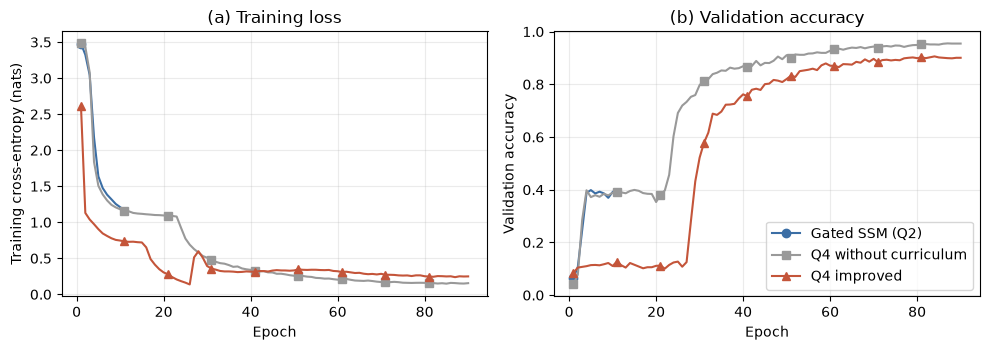

,Params,Best val acc,Best epoch,Epochs,Train s/epoch,Total train s,Inference samples/s
Run,,,,,,,
gated,"40,032",0.3987,5,10,30.7,307,"2,728"
improved_no_curriculum,"347,296",0.9553,87,90,6.9,618,"13,002"
improved,"347,296",0.9060,84,90,5.5,494,"12,952"


In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


def read_history(name):
    return json.loads(Path(f"runs/{name}/history.json").read_text())


fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
styles = {"gated": ("#3b6ea5", "o", "Gated SSM (Q2)"),
          "improved_no_curriculum": ("#999999", "s", "Q4 without curriculum"),
          "improved": ("#c4553a", "^", "Q4 improved")}
for name, (color, marker, label) in styles.items():
    history = read_history(name)
    epochs = [h["epoch"] for h in history]
    axes[0].plot(epochs, [h["train_loss"] for h in history], color=color, marker=marker, markevery=10, label=label)
    axes[1].plot(epochs, [h["val_accuracy"] for h in history], color=color, marker=marker, markevery=10, label=label)
axes[0].set(xlabel="Epoch", ylabel="Training cross-entropy (nats)", title="(a) Training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation accuracy", title="(b) Validation accuracy")
for ax in axes:
    ax.grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
fig.savefig("runs/q4_comparison.png", dpi=300)
plt.show()


def run_row(name):
    summary = json.loads(Path(f"runs/{name}/training_summary.json").read_text())
    history = read_history(name)
    best = max(history, key=lambda h: (h["val_accuracy"], -h["val_loss"]))
    return {"Run": name, "Params": summary["effective_trainable_parameters"], "Best val acc": best["val_accuracy"],
            "Best epoch": best["epoch"], "Epochs": len(history),
            "Train s/epoch": summary["mean_train_seconds_per_epoch"],
            "Total train s": sum(h["train_seconds"] for h in history),
            "Inference samples/s": summary["inference"]["forward_samples_per_second"]}


comparison = pd.DataFrame([run_row(name) for name in ["gated", "improved_no_curriculum", "improved"]]).set_index("Run")
display(comparison.style.format({"Params": "{:,}", "Best val acc": "{:.4f}", "Train s/epoch": "{:.1f}",
                                 "Total train s": "{:,.0f}", "Inference samples/s": "{:,.0f}"}))


,Params,Epochs,Best val acc,Best epoch,Val loss,First epoch > 0.5
Run,,,,,,
improved,"347,296",90,0.9060,84,0.2562,30
improved_no_curriculum,"347,296",90,0.9553,87,0.1501,24
long_d128,"347,296",300,0.9787,277,0.0767,24
long_d128_l3,"462,752",300,0.9800,281,0.0771,32
long_d192_n512,"836,704",300,0.9727,279,0.1066,111
long600_d128,"347,296",600,0.9887,573,0.0507,24
long600_d128_l3,"462,752",600,0.9893,532,0.0473,33
combo_n256,"462,752",400,0.9867,400,0.0381,45
combo600_n256,"462,752",600,0.7553,140,0.4339,43


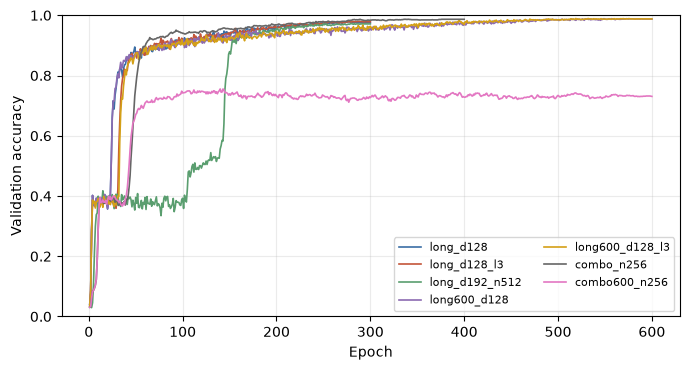

In [11]:
EXTENDED_RUNS = {
    "long_d128": ["--curriculum-epochs", 0, "--epochs", 300],
    "long_d128_l3": ["--curriculum-epochs", 0, "--epochs", 300, "--layers", 3],
    "long_d192_n512": ["--curriculum-epochs", 0, "--epochs", 300, "--d", 192, "--n", 512],
    "long600_d128": ["--curriculum-epochs", 0, "--epochs", 600],
    "long600_d128_l3": ["--curriculum-epochs", 0, "--epochs", 600, "--layers", 3],
    "combo_n256": ["--layers", 3, "--epochs", 400, "--ema", 0.999, "--curriculum-hold", 5, "--curriculum-epochs", 5,
                   "--store-weights", "1,1.5,2"],
    "combo600_n256": ["--layers", 3, "--epochs", 600, "--ema", 0.999, "--curriculum-hold", 5, "--curriculum-epochs", 5,
                      "--store-weights", "1,1.5,2"],
}
for name, extra in EXTENDED_RUNS.items():
    if not Path(f"runs/{name}/training_summary.json").exists():
        run_improved("train", "--data", DATA_DIR, "--out", f"runs/{name}", *extra)

Q4_RUNS = ["improved", "improved_no_curriculum", *EXTENDED_RUNS]
extended_rows = []
for name in Q4_RUNS:
    summary = json.loads(Path(f"runs/{name}/training_summary.json").read_text())
    history = read_history(name)
    extended_rows.append({"Run": name, "Params": summary["effective_trainable_parameters"], "Epochs": len(history),
                          "Best val acc": summary["best_validation_accuracy"], "Best epoch": summary["best_epoch"],
                          "Val loss": summary["best_validation_loss"],
                          "First epoch > 0.5": next((h["epoch"] for h in history if h["val_accuracy"] > 0.5), None)})
display(pd.DataFrame(extended_rows).set_index("Run").style.format(
    {"Params": "{:,}", "Best val acc": "{:.4f}", "Val loss": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(7, 3.8))
palette = ["#3b6ea5", "#c4553a", "#5a9e6f", "#8c6bb1", "#d4a017", "#666666", "#e377c2"]
for (name, color) in zip(EXTENDED_RUNS, palette):
    history = read_history(name)
    ax.plot([h["epoch"] for h in history], [h["val_accuracy"] for h in history], color=color, linewidth=1.2, label=name)
ax.set(xlabel="Epoch", ylabel="Validation accuracy", ylim=(0, 1))
ax.grid(alpha=0.25)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig("runs/q4_extended.png", dpi=300)
plt.show()


## Q4(b) — one final Kaggle submission

Choose your checkpoint using validation. Upload submission.csv manually to the course Kaggle page, use your student ID as team name, and select one final submission. Keep the exact CSV, checkpoint, configuration and Kaggle submission ID for grading. This notebook does not create a competition or upload predictions automatically.

In [12]:
import csv
import torch
from collections import defaultdict
from hw2_1 import evaluate, fixed_vocab, loader
from hw2_1_improved import ImprovedMemoryModel

validation = {name: torch.load(f"runs/{name}/best.pt", map_location="cpu", weights_only=True)["validation"] for name in Q4_RUNS}
params = {name: json.loads(Path(f"runs/{name}/training_summary.json").read_text())["effective_trainable_parameters"] for name in Q4_RUNS}
best_accuracy = max(v["accuracy"] for v in validation.values())
one_example = 1 / validation[Q4_RUNS[0]]["count"]
near_best = [name for name in Q4_RUNS if validation[name]["accuracy"] >= best_accuracy - one_example - 1e-9]
final_name = min(near_best, key=lambda name: (params[name], -validation[name]["accuracy"]))
FINAL_CHECKPOINT = Path(f"runs/{final_name}/best.pt")
print("Within one validation example of the best:", {k: (round(validation[k]["accuracy"], 4), params[k]) for k in near_best})
print("Selected (fewest parameters):", FINAL_CHECKPOINT)

subprocess.run([sys.executable, "hw2_1_improved.py", "predict", "--checkpoint", FINAL_CHECKPOINT,
                "--input", DATA_DIR / "test.jsonl", "--output", "submission.csv"], check=True)
with open("submission.csv") as f:
    submission = list(csv.DictReader(f))
test_ids = [json.loads(line)["id"] for line in (DATA_DIR / "test.jsonl").read_text().splitlines() if line.strip()]
assert [r["id"] for r in submission] == test_ids and len(set(test_ids)) == len(test_ids)
assert all(r["answer"] in {f"V{i}" for i in range(32)} for r in submission)
checkpoint = torch.load(FINAL_CHECKPOINT, map_location="cpu", weights_only=True)
print(f"submission.csv: {len(submission)} rows, columns {list(submission[0])}")
print("Final checkpoint:", FINAL_CHECKPOINT, "| epoch", checkpoint["epoch"], "| validation", checkpoint["validation"])
print("Model configuration:", checkpoint["config"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ImprovedMemoryModel(checkpoint["config"]).to(device)
model.load_state_dict(checkpoint["state_dict"])
_, rows = evaluate(model, loader(DATA_DIR / "val.jsonl", fixed_vocab(), 64), device, True)
groups = defaultdict(lambda: [0, 0])
errors = in_store_set = 0
for row in rows:
    tokens = row["tokens"]
    kinds = [tokens[i] for i in range(1, len(tokens) - 3, 4)]
    correct = row["prediction"] == row["answer"]
    groups[kinds.count("STORE")][0] += correct
    groups[kinds.count("STORE")][1] += 1
    if not correct:
        errors += 1
        in_store_set += row["prediction"] in {tokens[i + 2] for i in range(1, len(tokens) - 3, 4) if tokens[i] == "STORE"}
print({f"stores={k}": round(v[0] / v[1], 3) for k, v in sorted(groups.items())})
print(f"{in_store_set}/{errors} wrong predictions are a value of another STORE record")
for row in [r for r in rows if r["prediction"] != r["answer"]][:2]:
    print(row["prediction"], "instead of", row["answer"], "|", " ".join(row["tokens"]))


Within one validation example of the best: {'long600_d128': (0.9887, 347296), 'long600_d128_l3': (0.9893, 462752)}
Selected (fewest parameters): runs/long600_d128/best.pt


Wrote 2000 predictions to submission.csv


submission.csv: 2000 rows, columns ['id', 'answer']
Final checkpoint: runs/long600_d128/best.pt | epoch 573 | validation {'loss': 0.05070357926686605, 'accuracy': 0.9886666666666667, 'count': 1500}
Model configuration: {'d': 128, 'n': 256, 'layers': 2, 'dropout': 0.0, 'chunk': 16, 'head_hidden': 256}


{'stores=2': 1.0, 'stores=3': 0.99, 'stores=4': 0.976}
17/17 wrong predictions are a value of another STORE record
V12 instead of V21 | BOS NOISE K1 V23 SEP NOISE K13 V31 SEP NOISE K3 V8 SEP NOISE K25 V20 SEP STORE K14 V21 SEP NOISE K15 V0 SEP NOISE K14 V18 SEP NOISE K14 V22 SEP STORE K0 V12 SEP NOISE K22 V20 SEP NOISE K11 V20 SEP NOISE K19 V2 SEP NOISE K4 V18 SEP NOISE K12 V26 SEP NOISE K12 V0 SEP NOISE K27 V15 SEP NOISE K7 V5 SEP NOISE K13 V18 SEP NOISE K6 V28 SEP NOISE K26 V12 SEP STORE K25 V21 SEP NOISE K2 V9 SEP NOISE K9 V4 SEP NOISE K30 V16 SEP NOISE K20 V21 SEP NOISE K23 V20 SEP NOISE K14 V23 SEP NOISE K26 V4 SEP QUERY K14 ANSWER
V6 instead of V12 | BOS STORE K27 V12 SEP NOISE K1 V31 SEP NOISE K29 V3 SEP NOISE K28 V2 SEP STORE K15 V6 SEP STORE K22 V11 SEP STORE K18 V12 SEP NOISE K1 V14 SEP NOISE K5 V0 SEP NOISE K27 V13 SEP QUERY K27 ANSWER


In [13]:
import json

CONFIG_PATH = FINAL_CHECKPOINT.parent / "run_config.json"
config = json.loads(CONFIG_PATH.read_text())
config

{'command': 'train',
 'data': 'data',
 'out': 'runs/long600_d128',
 'd': 128,
 'n': 256,
 'layers': 2,
 'epochs': 600,
 'batch_size': 64,
 'seed': 42,
 'chunk': 16,
 'head_hidden': 256,
 'warmup_epochs': 1,
 'augment': 1,
 'curriculum_hold': 25,
 'curriculum_epochs': 0,
 'dropout': 0.0,
 'lr': 0.001,
 'weight_decay': 0.01,
 'device': 'auto',
 'environment': {'torch': '2.5.1+cu121',
  'python': '3.11.17',
  'device': 'cuda',
  'device_name': 'NVIDIA RTX A5000',
  'precision': 'float32'}}

## Written report — follow the assignment PDF

**Setup**
- Seed 42, PyTorch 2.5.1+cu121, Python 3.11.17, float32, shared server. Q1 to Q3 and the two 90-epoch Q4 runs used an RTX 3090, the longer Q4 runs an RTX A5000.
- Q1 to Q3: only the five TODOs filled, all provided settings kept (AdamW lr 1e-3, weight decay 0.01, batch 64, 10 epochs, clipping 1.0, d = N = 64, 2 blocks, dropout 0.1).
- Same initialization for both models: `a = sigmoid(theta_a)` evenly spaced in [0.5, 0.99], default init for B, C, D and W_g, gate bias 0.
- Training uses `train.jsonl` only, checkpoints are picked on `val.jsonl` only.

### Q1 — Basic SSM (10 points: implementation 5 + training results 3 + discussion 2)

- Best validation accuracy: **0.2340 at epoch 10** (validation loss 2.699). Curves are in the Q1/Q2 cell above.

**Q1(c) Implementation and discussion**
The basic SSM is a fixed-decay linear recurrence that restarts from zero for every sample, and the head reads the last real token. It trains steadily but is too weak to ignore NOISE in 10 epochs.

- Init: `theta_a` (N values) and bias-free linear layers B (d to N), C (N to d), D (d to d).
- Forward: input x is [batch, L, d]. `u = B(x)` is [batch, L, N]. Loop `h = a * h + u[:, t]` from `h = 0`. Stacked states are [batch, L, N]. Output `C(h) + D(x)` is [batch, L, d].
- State reset: `h` is created inside `forward`, so it starts at zero for every sample, layer and call.
- Causality: each step only uses current and earlier positions.
- Padding: right padding never affects earlier states. The model reads position `lengths - 1`, which is ANSWER for all 15,500 prompts I checked.
- Curves: train loss 3.48 to 2.57, val loss 3.43 to 2.70, still decreasing and close together, so no overfitting. The model is under-trained.
- Weakness: one fixed decay for all tokens, so NOISE is mixed in like STORE. Accuracy drops from 0.269 to 0.191 as NOISE records grow from 6-12 to 21-28.

### Q2 — Gated SSM (10 points: implementation 5 + training results 3 + discussion 2)

- Best validation accuracy: **0.3987 at epoch 5** (validation loss 1.527).

**Q2(c) Implementation and discussion**
The gate lets each token decide how much of the state to overwrite. This filters NOISE and raises accuracy from 0.234 to 0.399, but the model still cannot tell which value belongs to which key.

- Gate: `g = sigmoid(W_g x + b_g)` with N outputs, bias starts at 0, so each gate depends only on the current token.
- Update: candidate `a * h + B x_t`, then `h = (1 - g_t) * h + g_t * candidate`. Output `C h + D x`.
- g near 0: the old state is copied and the token is ignored.
- g near 1: same as the basic SSM step, the token is written and old content decays by `a`.
- Gating helped: 0.234 to 0.399 under identical settings.
- NOISE is filtered: accuracy no longer drops with more noise (0.401, 0.391, 0.403).
- Binding is not learned: accuracy is about 1 / (number of stored pairs), 0.536, 0.362, 0.304 for 2, 3, 4 pairs, and 899 of 902 errors are the value of another STORE record. The model guesses among the stored values.

### Q3 — Comparison (5 points: measurements 3 + discussion 2)
- Hardware: RTX 3090, CUDA 12.1, PyTorch 2.5.1, float32, batch 64.

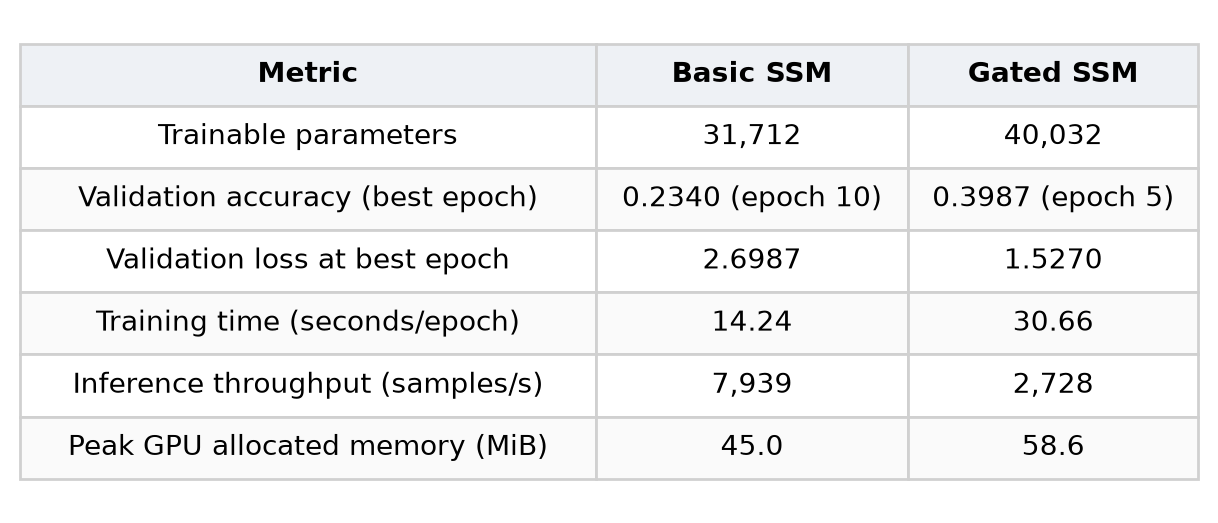

**Q3(b) Implementation and discussion**
The gated model is larger and slower because each step does more work, but it is much more accurate because it can skip NOISE. Both models were timed with the same procedure.

- Training time: training loop only, with `torch.cuda.synchronize` before and after, mean over 10 epochs.
- Throughput: eval mode, `torch.no_grad()`, 3 warm-up passes, 10 timed passes, synchronized.
- Memory: `torch.cuda.max_memory_allocated`, reset every epoch, maximum reported.
- Same GPU, precision, batch size, data order and seed for both models.
- Trade-off: gated has 26% more parameters, 2.2x training time, 2.9x lower throughput and 30% more memory, for +0.165 accuracy.
- Reason 1, computation: the Python loop over 124 steps dominates time, and a gated step launches about twice as many kernels and stores extra tensors.
- Reason 2, selection: the gain comes from input-dependent gating, not from size. A basic SSM with the same parameters still cannot ignore NOISE.
- Reason 3, randomness: one seed only, gated jumps from 0.25 to 0.39 at epoch 4, basic is still improving at epoch 10.

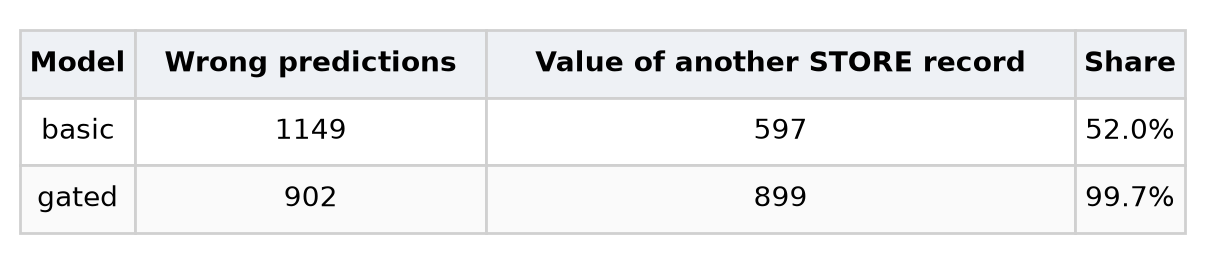

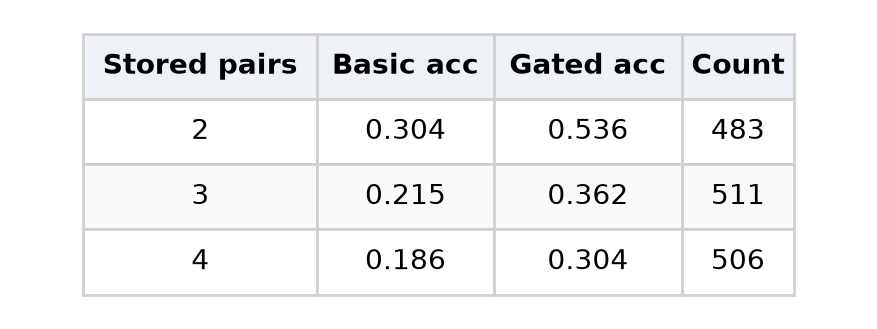

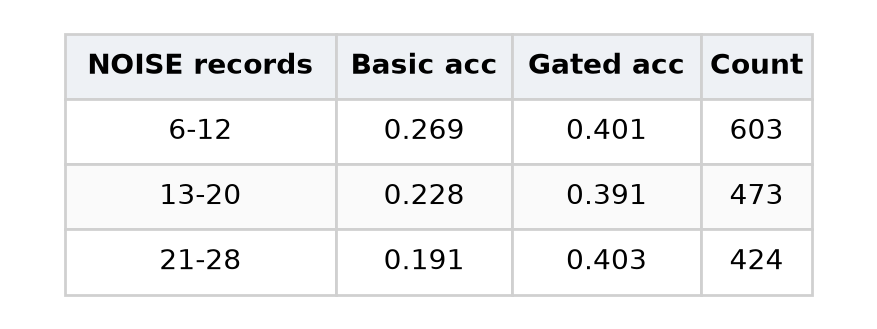

- Failure (basic): `STORE K26 V0, NOISE K26 V8, STORE K29 V19, QUERY K26` gives V19, the latest stored value.
- Failure (gated): `STORE K19 V21, STORE K20 V19, NOISE K20 V17, QUERY K20` gives V21. Noise is ignored, but the wrong stored key is used.

### Q4(a) — Improvement and validation results (3 points)

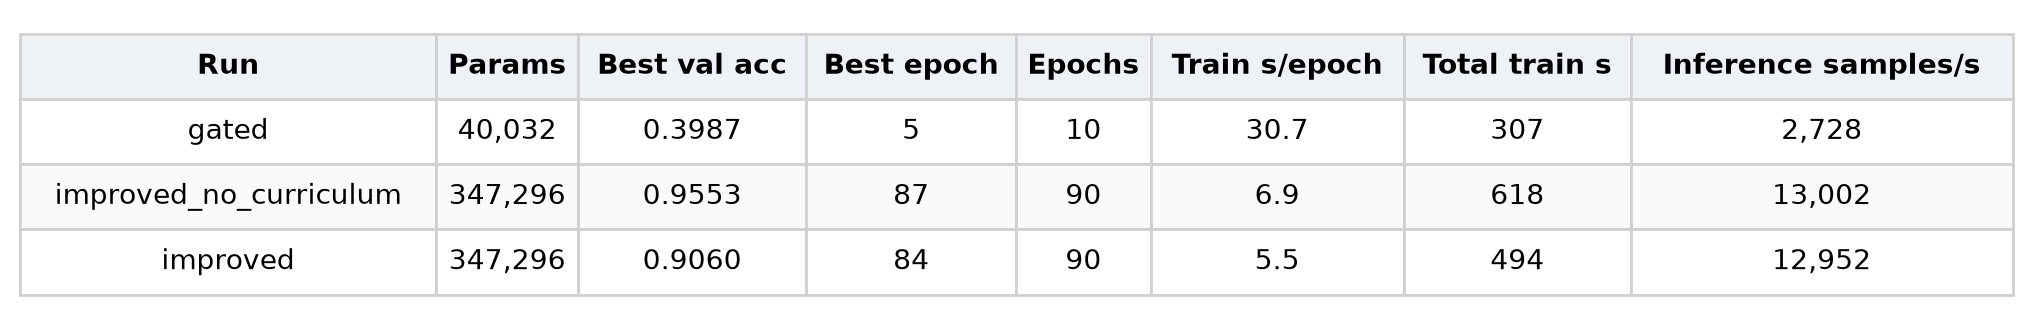

- `improved_no_curriculum`: improved model, 90 epochs. `improved`: same model with the curriculum.
- Final model (`long600_d128`): same 2-block model, 347,296 parameters, 600 epochs, **0.9887 at epoch 573** (Q2 gated: 0.3987).
- Final run cost: 13.6 s/epoch, 8,179 s total, 2,886 samples/s (shared GPU, so times are inflated).
- Seed 43 check at 90 epochs: 0.9553 (seed 42: 0.9553), with curriculum 0.9073 (seed 42: 0.9060).

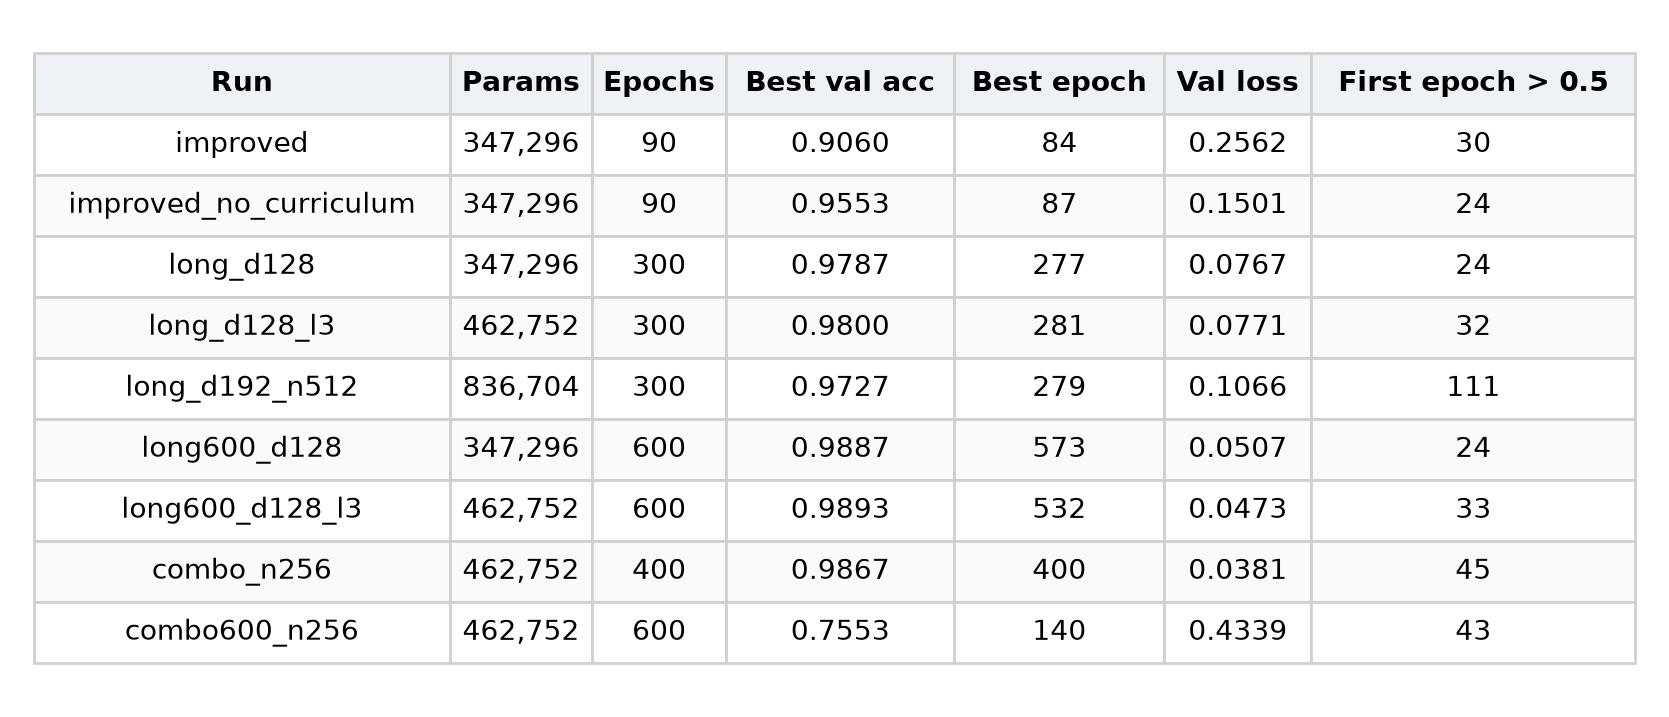

### Q4(b) — Kaggle competition (20 points)

- Team name: **314540080**
- Final submission: `submissions/submission_long600_d128_val0.9887.csv`
- Checkpoint: `runs/long600_d128/best.pt` (epoch 573, validation accuracy 0.9887, loss 0.0507)
- Configuration: `runs/long600_d128/run_config.json`. Gated SSM with d = 128, N = 256 and 2 blocks, dropout 0, query-key head with 256 hidden units, train-only augmentation, AdamW (lr 1e-3, weight decay 0.01), 1 warm-up epoch then cosine decay, 600 epochs, batch 64, seed 42. Command: `python hw2_1_improved.py train --data data --out runs/long600_d128 --curriculum-epochs 0 --epochs 600`
- Kaggle submission ID: **57664679**
- Public score: **0.98666**

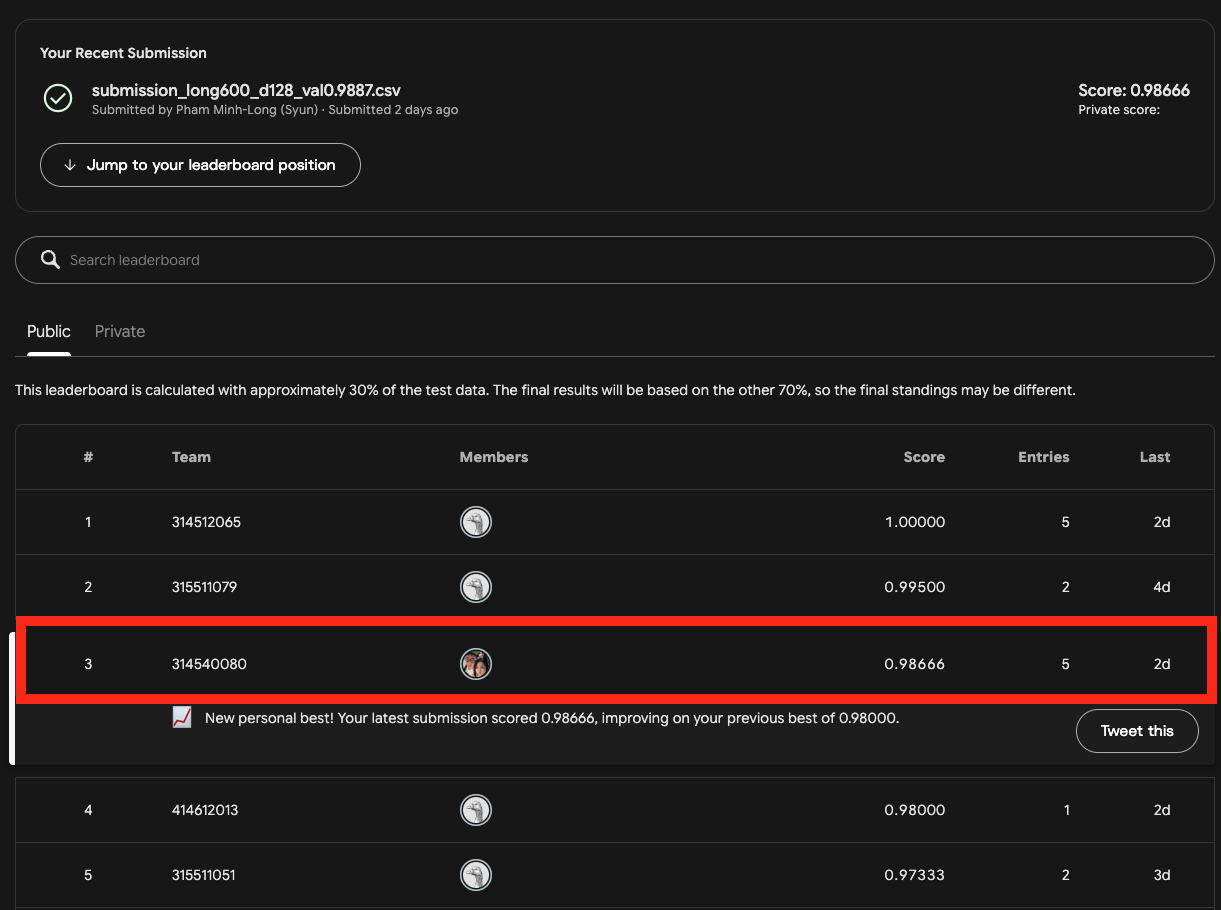

### Q4(c) — Implementation and discussion (2 points)

I kept the gated SSM update and changed the state size, the head, the data augmentation and the training length. Augmentation removed overfitting, so training longer kept improving accuracy from 0.96 to 0.99.

**What I changed** (the gated SSM update and token-only inputs are kept)
- Bigger state: d 64 to 128, N 64 to 256, still 2 blocks.
- Head: MLP on [s, q, s * q], where s is the ANSWER vector and q the query-key embedding. The product lets the head match memory to the query.
- Augmentation from `train.jsonl` only: rename keys and values, shuffle records, re-pick the query among valid STORE keys and update the label.
- Schedule: 1 warm-up epoch, cosine decay from lr 1e-3, dropout 0, 600 epochs.
- Speed: same recurrence computed in chunks of 16 steps, max difference 1.3e-15 against the loop.

**Why**
- Q2 showed the model filters noise but cannot bind values to keys. Binding needs a larger state and a query-aware readout.
- Augmentation stops memorization, so long training keeps improving instead of overfitting.

**Effect on validation**
- All runs first sit at about 0.40, then escape suddenly (epoch 24 for 2 blocks, about 33 for 3 blocks).
- 2 blocks: 0.9553 at 90 epochs, 0.9787 at 300, 0.9887 at 600 (+0.590 over Q2).
- Remaining 17 errors are all another stored value. Accuracy is 1.000, 0.990, 0.976 for 2, 3, 4 pairs.
- Curriculum: about 0.05 worse at 90 epochs (both seeds).
- Wider state (d = 192, N = 512): escapes at about epoch 110, ends at 0.9727.
- Third block: 0.9893, one validation example better, 33% more parameters.
- EMA + short curriculum + weighted sampling: 0.9867 at 400 epochs, but the same recipe at 600 epochs got stuck at 0.73. Training is quite random, so small gaps are noise.

**Checkpoint selection and CSV**
- Each run keeps its best validation epoch (ties broken by lower loss).
- The two 600-epoch models differ by one validation example, so I picked the smaller one (2 blocks).
- The CSV is written by `hw2_1_improved.py predict` and checked for exactly one row per test id and answers in V0 to V31.
- Test labels were never available.
